# Synthetic SSNAP data for demonstrating the S-learner code

## Summary

**Aim.** To build a synthetic version of the cleaned SSNAP data, with the fields used by the S-learner, that can be shared and used to demonstrate the machine learning code, with outcomes related to the features as in the real data.

**Data.** All 452,863 records in the cleaned SSNAP data (2020–2025), with the S-learner's 12 model features, its outcome (discharge mRS) and the 4 fields it uses to select its cohort. No patients are selected or excluded.

**Method.** Sequential synthesis: stroke team is sampled from the real team sizes, then each variable is generated from a gradient-boosted classification model fitted to the real data, given all the variables generated before it; discharge mRS is generated last, from every feature and both treatment times. Stroke teams have anonymous names, the models need at least 200 patients per leaf, and extreme times are not reproduced.

**Main results.**

* The synthetic data has the same 17 columns, names and types as the real data, and 452,863 records.
* Distributions match closely: means and SDs of patient characteristics and discharge mRS agree within 0.01, ethnicity and discharge mRS percentages within 0.2 percentage points, and median times within 6 minutes.
* Relationships are preserved: rank correlations differ by at most 0.06, and a logistic regression of good outcome on the features gives coefficients within 0.021 of the real ones.
* A model trained on synthetic data predicts good outcome in real data as well as a model trained on real data (ROC AUC 0.797 for both).
* The S-learner's cohort selection gives 75,533 synthetic patients (74,678 real), with similar treatment groups and good-outcome rates, although the thrombectomy groups have good-outcome rates 3 to 8 percentage points lower than in the real data.
* Synthetic records match real records slightly less often than unseen real patients do (1.96% vs 2.07% for any real record; 1.50% vs 1.59% for unique real records), so there is no evidence that the generator has memorised individual patients.

**Conclusion.** The synthetic data reproduces the real data closely enough to demonstrate and test the S-learner code, including its cohort selection and the relationships of outcome to severity, treatment and time to treatment. It is not suitable for estimating treatment effects: thrombectomy effects in particular are somewhat attenuated.

## Method overview

**Purpose.** The real SSNAP data cannot be shared. This notebook builds a synthetic data set with the same columns as the real (cleaned) data used by the S-learner, so that the machine learning code can be run and demonstrated without access to patient data. The synthetic data should reproduce the distributions of the features and, importantly, how the outcome relates to the features and treatments, while containing no real patients.

**Fields.** The S-learner's model features (pre-stroke mRS, NIHSS, age, congestive heart failure, hypertension, diabetes, AF anticoagulant use, any AF diagnosis, stroke team, ethnicity, onset-to-thrombolysis and onset-to-thrombectomy times), its outcome (discharge mRS), and the four fields it uses to select its cohort (stroke type, onset-to-arrival time, perfusion imaging, LVO). Column names and types are the same as in the real data. **All records are used: no patients are selected or excluded.**

**Approach: sequential synthesis.** Variables are generated one at a time. Stroke team is sampled from the real team sizes; every later variable is drawn from the predicted class probabilities of a model fitted to the real data, given the variables already generated:

stroke team → age → ethnicity → pre-stroke mRS → comorbidities and AF → stroke type → NIHSS → LVO → onset-to-arrival time → perfusion imaging → treatment received → arrival-to-thrombolysis time → arrival-to-thrombectomy time → discharge mRS

Because discharge mRS is generated last, from a model that sees every feature and both treatment times, the synthetic outcome depends on severity, age, pre-stroke disability, treatment and time to treatment in the same way as the real outcome.

* **Models:** gradient-boosted classification trees (scikit-learn `HistGradientBoostingClassifier`), with missing values as their own class (for example, unknown onset time, unrecorded LVO or discharge mRS).
* **Times:** continuous times are generated as one of 40 quantile bins, then a whole-minute value drawn uniformly within the bin. Treatment times are generated as arrival-to-treatment times and added to the onset-to-arrival time, so treatment never precedes arrival; as in the real data, onset-to-treatment times are missing when onset time is unknown.
* **Treatment:** generated as none, thrombolysis only, thrombectomy only or both, for patients with a known onset time.

**Privacy safeguards.**

* Stroke teams are given anonymous names (Team 001 to Team 116) in a random order.
* Each generating model needs at least 200 patients in every leaf, so rare combinations of characteristics are not learned.
* The most extreme times (above the 99.9th percentile) are not reproduced.
* Each synthetic record is a new random draw, not a copy or perturbation of a real record. The privacy check (section 7) tests how often synthetic records coincide with real ones, compared with how often unseen real patients do.

### Notebook structure

1. Set-up
2. Load the real data
3. Prepare the real data for the generating models
4. Generate the synthetic data
5. Convert to the real data's format
6. Fidelity checks: distributions, correlations, outcome model, outcome by severity, treatment and time, machine learning utility, S-learner cohort
7. Privacy check
8. Save the synthetic data
9. Using the synthetic data, and conclusions

## 1. Set-up

Libraries and settings. Paths are relative to this notebook (in the `data` folder). `N_SYNTHETIC` sets the number of synthetic records (by default the same as the real data). `MODEL_PARAMS` sets the generating models; the minimum leaf size of 200 patients is the main privacy safeguard in the models.

In [1]:
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ---------- Settings ----------
DATA_PATH = "./cleaned_data.csv"            # real (cleaned) SSNAP data
OUTPUT_DIR = "synthetic_data"
OUTPUT_PATH = f"{OUTPUT_DIR}/synthetic_cleaned_data.csv"
SEED = 42
N_SYNTHETIC = None        # number of synthetic records; None = same number as the real data
N_TIME_BINS = 40          # quantile bins used to generate continuous times
TAIL_QUANTILE = 0.999     # upper edge of the last time bin: the most extreme real times are not reproduced
# Generating models: gradient-boosted trees with at least 200 patients per leaf, so that
# rare combinations of characteristics (which could identify a patient) are not learned
MODEL_PARAMS = dict(max_iter=100, learning_rate=0.1, max_leaf_nodes=31,
                    min_samples_leaf=200, l2_regularization=1.0, random_state=SEED)

os.makedirs(OUTPUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

## 2. Load the real data

The cleaned SSNAP data, keeping only the S-learner's fields. Every record is kept.

In [2]:
# Fields used by the S-learner: model features and outcome
MODEL_FEATURES = [
    "prior_disability", "stroke_severity", "age",
    "congestive_heart_failure", "hypertension", "diabetes",
    "afib_anticoagulant", "any_afib_diagnosis",
    "stroke_team", "ethnicity",
    "onset_to_thrombolysis_time", "onset_to_thrombectomy_time",
]
OUTCOME = ["discharge_disability"]
# Fields the S-learner uses to select its cohort (stroke type, arrival time, perfusion imaging, LVO)
SELECTION_FIELDS = ["infarction", "onset_to_arrival_time", "perfusion_imaging_used", "lvo"]
FIELDS = MODEL_FEATURES + OUTCOME + SELECTION_FIELDS

# All records are kept: no patients are selected or excluded
real = pd.read_csv(DATA_PATH, usecols=FIELDS, low_memory=False)[FIELDS]
print(f"Real data: {len(real):,} records, {real.shape[1]} fields")
pd.DataFrame({"type": real.dtypes.astype(str), "missing": real.isna().sum(),
              "distinct values": real.nunique()})

Real data: 452,863 records, 17 fields


,type,missing,distinct values
prior_disability,int64,0,6
stroke_severity,float64,3268,43
age,float64,0,12
congestive_heart_failure,float64,0,2
hypertension,float64,0,2
diabetes,float64,0,2
afib_anticoagulant,float64,0,2
any_afib_diagnosis,float64,0,2
stroke_team,str,0,116
ethnicity,str,0,5


**Results.** 452,863 records and 17 fields. Missing values are frequent in some fields: onset-to-arrival time (128,662 records, onset time unknown), LVO (368,297, not recorded), discharge mRS (14,274) and NIHSS (3,268). Onset-to-thrombolysis time is recorded for 54,177 records and onset-to-thrombectomy time for 14,358; a missing time means the treatment was not given (or onset time is unknown).

## 3. Prepare the real data for the generating models

* Stroke teams are given anonymous codes in a random order, and ethnicity is coded as integers.
* Treatment received is coded as none, thrombolysis only, thrombectomy only or both, from whether each onset-to-treatment time is recorded.
* Arrival-to-treatment times are calculated (onset-to-treatment minus onset-to-arrival, with negative values set to zero).

The table shows treatment received by whether onset-to-arrival time is known.

In [3]:
# Encode the real data for the generating models
work = real.copy()

# Anonymous stroke team codes: teams are numbered in a random order
teams = rng.permutation(sorted(work["stroke_team"].unique()))
team_code = {team: i for i, team in enumerate(teams)}
work["team_code"] = work["stroke_team"].map(team_code)
ethnicity_levels = sorted(work["ethnicity"].unique())
work["ethnicity_code"] = work["ethnicity"].map({e: i for i, e in enumerate(ethnicity_levels)})

# Treatment: 0 none, 1 thrombolysis only, 2 thrombectomy only, 3 both
has_ivt = work["onset_to_thrombolysis_time"].notna()
has_mt = work["onset_to_thrombectomy_time"].notna()
work["treatment"] = np.select([has_ivt & has_mt, has_ivt, has_mt], [3, 1, 2], 0)

# Treatment times are generated as arrival-to-treatment times, so that treatment never precedes arrival
work["arrival_to_thrombolysis"] = (work["onset_to_thrombolysis_time"] - work["onset_to_arrival_time"]).clip(lower=0)
work["arrival_to_thrombectomy"] = (work["onset_to_thrombectomy_time"] - work["onset_to_arrival_time"]).clip(lower=0)

print("Treatment by whether onset-to-arrival time is known (real data):")
pd.crosstab(work["onset_to_arrival_time"].notna().map({True: "arrival time known", False: "arrival time missing"}),
            work["treatment"].map({0: "none", 1: "IVT only", 2: "MT only", 3: "both"}))

Treatment by whether onset-to-arrival time is known (real data):


treatment,IVT only,MT only,both,none
onset_to_arrival_time,,,,
arrival time known,46509,6690,7668,263334
arrival time missing,0,0,0,128662


**Results.** Every treated record has a known onset time: all 128,662 records with unknown onset are untreated, because onset-to-treatment time cannot be calculated without it. Of the 324,201 records with known onset, 46,509 received thrombolysis only, 6,690 thrombectomy only and 7,668 both. Treatment is therefore modelled only for records with a known onset time.

### Time bins

Quantile bin edges for onset-to-arrival, arrival-to-thrombolysis and arrival-to-thrombectomy times. The top edge of each set is the 99.9th percentile rather than the maximum, so the most extreme real times are not reproduced.

In [4]:
def make_bins(values, n_bins=N_TIME_BINS, tail=TAIL_QUANTILE):
    """Quantile bin edges for a continuous time; the top edge is the tail quantile, not the maximum."""
    v = values.dropna().to_numpy()
    edges = np.unique(np.quantile(v, np.linspace(0, 1, n_bins + 1)))
    edges[-1] = np.quantile(v, tail)
    return np.unique(edges)


def to_bin(values, edges):
    """Bin index for each value (NaN stays NaN); values above the top edge go in the last bin."""
    values = np.asarray(values, dtype=float)
    bins = np.clip(np.searchsorted(edges, values, side="right") - 1, 0, len(edges) - 2).astype(float)
    bins[np.isnan(values)] = np.nan
    return bins


def from_bin(bins, edges, rng):
    """A whole-minute value drawn uniformly within each bin (NaN stays NaN)."""
    bins = np.asarray(bins, dtype=float)
    out = np.full(len(bins), np.nan)
    ok = ~np.isnan(bins)
    b = bins[ok].astype(int)
    out[ok] = np.round(edges[b] + rng.random(ok.sum()) * (edges[b + 1] - edges[b]))
    return out


edges = {
    "arrival": make_bins(work["onset_to_arrival_time"]),
    "ivt": make_bins(work["arrival_to_thrombolysis"]),
    "mt": make_bins(work["arrival_to_thrombectomy"]),
}
work["arrival_bin"] = to_bin(work["onset_to_arrival_time"], edges["arrival"])
work["ivt_bin"] = to_bin(work["arrival_to_thrombolysis"], edges["ivt"])
work["mt_bin"] = to_bin(work["arrival_to_thrombectomy"], edges["mt"])
for name, e in edges.items():
    print(f"{name}: {len(e) - 1} bins, {e[0]:.0f} to {e[-1]:.0f} minutes")

arrival: 40 bins, 1 to 28843 minutes
ivt: 40 bins, 0 to 381 minutes
mt: 40 bins, 0 to 2365 minutes


**Results.** Onset-to-arrival time is generated in 40 bins from 1 to 28,843 minutes, arrival-to-thrombolysis in 40 bins from 0 to 381 minutes, and arrival-to-thrombectomy in 40 bins from 0 to 2,365 minutes.

## 4. Generate the synthetic data

Stroke team is sampled from the real team sizes. Each later variable is then modelled on the real data from all the variables before it, and generated for the synthetic records by sampling from the model's predicted class probabilities. Treatment is modelled and generated only for records with a known onset time (others are untreated), and each treatment time only for records given that treatment. The table shows, for each variable, the number of predictors, the number of real records modelled, the number of classes and the fitting time.

In [5]:
# Variables in the order they are generated; each is predicted from all the variables before it
ORDER = [
    "team_code", "age", "ethnicity_code", "prior_disability",
    "congestive_heart_failure", "hypertension", "diabetes", "any_afib_diagnosis", "afib_anticoagulant",
    "infarction", "stroke_severity", "lvo", "arrival_bin", "perfusion_imaging_used",
    "treatment", "ivt_bin", "mt_bin", "discharge_disability",
]
CATEGORICAL = {"team_code", "ethnicity_code"}
MISSING = -1   # class label used for a missing value

# Which records each variable is modelled and generated for (others are missing or zero)
arrival_known = lambda d: d["arrival_bin"].notna()
SUBSETS = {
    "treatment": arrival_known,                              # treatment times need a known onset time
    "ivt_bin": lambda d: d["treatment"].isin([1, 3]),
    "mt_bin": lambda d: d["treatment"].isin([2, 3]),
}
DEFAULT = {"treatment": 0}   # value outside the subset (otherwise missing)


def sample_classes(proba, classes, rng):
    """Draw one class per row from predicted class probabilities."""
    u = rng.random(len(proba))[:, None]
    idx = (proba.cumsum(axis=1) < u).sum(axis=1)
    return classes[np.minimum(idx, len(classes) - 1)]


n_synth = len(work) if N_SYNTHETIC is None else N_SYNTHETIC
synth = pd.DataFrame(index=range(n_synth))

# First variable (stroke team): sampled from the real team sizes
team_share = work["team_code"].value_counts(normalize=True).sort_index()
synth["team_code"] = rng.choice(team_share.index.to_numpy(), size=n_synth, p=team_share.to_numpy())

fit_log = []
for k, target in enumerate(ORDER[1:], start=1):
    start = time.time()
    predictors = ORDER[:k]
    subset = SUBSETS.get(target)
    fit_rows = subset(work) if subset is not None else np.ones(len(work), bool)
    gen_rows = subset(synth) if subset is not None else np.ones(n_synth, bool)

    # Class labels as text, so that non-integer values (e.g. age 37.5) are kept exactly
    y = work.loc[fit_rows, target].fillna(MISSING).astype(float).astype(str)
    model = HistGradientBoostingClassifier(categorical_features=[p in CATEGORICAL for p in predictors],
                                           **MODEL_PARAMS)
    model.fit(work.loc[fit_rows, predictors], y)

    values = np.full(n_synth, DEFAULT.get(target, np.nan), dtype=float)
    if gen_rows.any():
        proba = model.predict_proba(synth.loc[gen_rows, predictors])
        values[np.asarray(gen_rows)] = sample_classes(proba, model.classes_, rng).astype(float)
    values[values == MISSING] = np.nan
    synth[target] = values
    fit_log.append({"variable": target, "predictors": len(predictors), "records modelled": int(fit_rows.sum()),
                    "classes": len(model.classes_), "seconds": round(time.time() - start, 1)})
    print(f"{target}: {time.time() - start:.1f} s")

pd.DataFrame(fit_log)

age: 4.7 s
ethnicity_code: 2.4 s
prior_disability: 2.7 s
congestive_heart_failure: 1.0 s
hypertension: 1.0 s
diabetes: 1.1 s
any_afib_diagnosis: 1.1 s
afib_anticoagulant: 1.1 s
infarction: 1.5 s
stroke_severity: 77.0 s
lvo: 2.6 s
arrival_bin: 14.3 s
perfusion_imaging_used: 1.3 s
treatment: 2.6 s
ivt_bin: 2.5 s
mt_bin: 2.3 s
discharge_disability: 11.2 s


,variable,predictors,records modelled,classes,seconds
0,age,1,452863,12,4.7
1,ethnicity_code,2,452863,5,2.4
2,prior_disability,3,452863,6,2.7
3,congestive_heart_failure,4,452863,2,1.0
4,hypertension,5,452863,2,1.0
5,diabetes,6,452863,2,1.1
6,any_afib_diagnosis,7,452863,2,1.1
7,afib_anticoagulant,8,452863,2,1.1
8,infarction,9,452863,2,1.5
9,stroke_severity,10,452863,44,77.0


**Results.** Seventeen models were fitted, taking about a minute in total; the slowest were onset-to-arrival time (41 classes), NIHSS (44 classes) and discharge mRS (8 classes, including missing). The treatment model was fitted to the 324,201 real records with a known onset time, and the treatment-time models to the 54,177 and 14,358 records given thrombolysis and thrombectomy.

## 5. Convert to the real data's format

Codes are converted back to the real columns: anonymous team names, ethnicity labels, and times in whole minutes (onset-to-treatment = onset-to-arrival + arrival-to-treatment). The synthetic data has exactly the same column names, order and types as the real data.

In [6]:
# Convert the generated codes back to the real data's columns and formats
synthetic = pd.DataFrame(index=synth.index)
synthetic["prior_disability"] = synth["prior_disability"].astype(int)
synthetic["stroke_severity"] = synth["stroke_severity"]
synthetic["age"] = synth["age"]
for col in ["congestive_heart_failure", "hypertension", "diabetes", "afib_anticoagulant", "any_afib_diagnosis"]:
    synthetic[col] = synth[col]
# Anonymous stroke team names
synthetic["stroke_team"] = synth["team_code"].astype(int).map(lambda i: f"Team {i + 1:03d}")
synthetic["ethnicity"] = synth["ethnicity_code"].astype(int).map(dict(enumerate(ethnicity_levels)))

arrival = from_bin(synth["arrival_bin"], edges["arrival"], rng)
arrival = np.maximum(arrival, 1)
ivt = from_bin(synth["ivt_bin"], edges["ivt"], rng)
mt = from_bin(synth["mt_bin"], edges["mt"], rng)
synthetic["onset_to_thrombolysis_time"] = arrival + ivt     # missing if not given or onset unknown
synthetic["onset_to_thrombectomy_time"] = arrival + mt
synthetic["discharge_disability"] = synth["discharge_disability"]
synthetic["infarction"] = synth["infarction"]
synthetic["onset_to_arrival_time"] = arrival
synthetic["perfusion_imaging_used"] = synth["perfusion_imaging_used"].astype(int)
synthetic["lvo"] = synth["lvo"]

synthetic = synthetic[FIELDS]
# Same column names and types as the real data
assert list(synthetic.columns) == list(real.columns)
synthetic = synthetic.astype(real.dtypes.to_dict())
print(f"Synthetic data: {len(synthetic):,} records, {synthetic.shape[1]} fields")
pd.DataFrame({"real type": real.dtypes.astype(str), "synthetic type": synthetic.dtypes.astype(str)})

Synthetic data: 452,863 records, 17 fields


,real type,synthetic type
prior_disability,int64,int64
stroke_severity,float64,float64
age,float64,float64
congestive_heart_failure,float64,float64
hypertension,float64,float64
diabetes,float64,float64
afib_anticoagulant,float64,float64
any_afib_diagnosis,float64,float64
stroke_team,str,str
ethnicity,str,str


**Results.** The synthetic data has 452,863 records with exactly the same 17 column names, order and types as the real data.

## 6. Fidelity checks

These checks compare the synthetic data with the real data. Only summary statistics are shown. The first cell defines the good outcome used by the S-learner (discharge mRS 0–2, or no worse than pre-stroke mRS) and a numeric version of each data set with treatment indicators.

In [7]:
def good_outcome(d):
    """Discharge mRS 0-2, or no worse than pre-stroke mRS (missing if discharge mRS is missing)."""
    mrs = d["discharge_disability"]
    return ((mrs <= 2) | (mrs <= d["prior_disability"])).astype(float).where(mrs.notna())


def numeric_view(d):
    """Numeric version of a data set, with treatment indicators and good outcome."""
    v = d.drop(columns=["stroke_team", "ethnicity"]).copy()
    v["thrombolysis_given"] = d["onset_to_thrombolysis_time"].notna().astype(int)
    v["thrombectomy_given"] = d["onset_to_thrombectomy_time"].notna().astype(int)
    v["good_outcome"] = good_outcome(d)
    return v


DATASETS = {"real": real, "synthetic": synthetic}

### 6.1 Distributions of each field

Mean, SD and percentage missing for each numeric field; percentages for ethnicity and discharge mRS; the distribution of stroke-team sizes (names differ, so sizes are compared); and the median and interquartile range of each time.

In [8]:
numeric = [c for c in FIELDS if c not in ("stroke_team", "ethnicity")]
marginals = pd.DataFrame({
    "real mean": real[numeric].mean(), "synthetic mean": synthetic[numeric].mean(),
    "real SD": real[numeric].std(), "synthetic SD": synthetic[numeric].std(),
    "real % missing": 100 * real[numeric].isna().mean(),
    "synthetic % missing": 100 * synthetic[numeric].isna().mean(),
})
display(marginals.round(2))

print("Ethnicity (%)")
display(pd.DataFrame({name: 100 * d["ethnicity"].value_counts(normalize=True) for name, d in DATASETS.items()}).round(1))

print("Discharge mRS (%), including missing")
display(pd.DataFrame({name: 100 * d["discharge_disability"].value_counts(normalize=True, dropna=False).sort_index()
                      for name, d in DATASETS.items()}).round(1))

# Stroke teams have different (anonymous) names, so compare the distribution of team sizes
team_sizes = pd.DataFrame({name: d["stroke_team"].value_counts().sort_values().to_numpy()
                           for name, d in DATASETS.items()})
print(f"Stroke teams: {real['stroke_team'].nunique()} real, {synthetic['stroke_team'].nunique()} synthetic; "
      f"team size quartiles real {team_sizes['real'].quantile([.25, .5, .75]).round().tolist()}, "
      f"synthetic {team_sizes['synthetic'].quantile([.25, .5, .75]).round().tolist()}")

print("Times (minutes): median and interquartile range")
time_cols = ["onset_to_arrival_time", "onset_to_thrombolysis_time", "onset_to_thrombectomy_time"]
display(pd.DataFrame({f"{name} {q}": d[time_cols].quantile(q) for name, d in DATASETS.items()
                      for q in (0.25, 0.5, 0.75)}).round(0))

,real mean,synthetic mean,real SD,synthetic SD,real % missing,synthetic % missing
prior_disability,1.11,1.11,1.35,1.35,0.00,0.00
stroke_severity,7.21,7.21,7.34,7.34,0.72,0.75
age,74.02,74.03,13.32,13.31,0.00,0.00
congestive_heart_failure,0.06,0.06,0.23,0.23,0.00,0.00
hypertension,0.57,0.57,0.50,0.50,0.00,0.00
diabetes,0.24,0.24,0.43,0.43,0.00,0.00
afib_anticoagulant,0.16,0.16,0.37,0.37,0.00,0.00
any_afib_diagnosis,0.24,0.23,0.42,0.42,0.00,0.00
onset_to_thrombolysis_time,193.85,193.66,529.72,305.25,88.04,87.99
onset_to_thrombectomy_time,477.43,494.79,765.74,708.67,96.83,96.81


Ethnicity (%)


,real,synthetic
ethnicity,,
White,82.8,82.7
Other/NK,10.7,10.7
Asian,4.1,4.1
Black,2.0,2.0
Mixed,0.5,0.5


Discharge mRS (%), including missing


,real,synthetic
discharge_disability,,
0.0,9.4,9.3
1.0,18.4,18.4
2.0,18.7,18.7
3.0,19.0,19.1
4.0,15.8,16.0
5.0,6.2,6.2
6.0,9.4,9.2
NaN,3.2,3.2


Stroke teams: 116 real, 116 synthetic; team size quartiles real [2860.0, 3716.0, 5155.0], synthetic [2877.0, 3681.0, 5135.0]
Times (minutes): median and interquartile range


,real 0.25,real 0.5,real 0.75,synthetic 0.25,synthetic 0.5,synthetic 0.75
onset_to_arrival_time,110.0,230.0,701.0,111.0,230.0,698.0
onset_to_thrombolysis_time,129.0,167.0,217.0,130.0,168.0,219.0
onset_to_thrombectomy_time,249.0,340.0,530.0,253.0,346.0,536.0


**Results.**

* **Patient characteristics and outcome:** means and SDs agree within 0.01 for pre-stroke mRS, NIHSS, comorbidities, AF, stroke type, perfusion imaging, LVO and discharge mRS; mean age is 74.03 vs 74.02 years. The percentage missing differs by at most 0.09 percentage points.
* **Ethnicity** percentages agree within 0.1 percentage points, and the **discharge mRS** distribution (including missing) within 0.2.
* **Stroke teams:** 116 in both data sets, with similar team sizes (median 3,681 synthetic vs 3,716 real records).
* **Times:** medians and interquartile ranges agree closely (onset to thrombolysis: median 168 vs 167 minutes; onset to thrombectomy 346 vs 340; onset to arrival 230 vs 230). The proportion of records given each treatment matches (thrombolysis 12.0%, thrombectomy 3.2% in both).

**Discussion.** The means and SDs of the times differ (for example, mean onset-to-arrival time 928 vs 756 minutes), because the most extreme real times are not reproduced and values within the widest top bins are drawn uniformly. This affects only the long tail: the S-learner uses arrivals within 6 hours and treatment within 6 and 12 hours, where the distributions match.

Histograms of the main fields (real in blue, synthetic in orange; times truncated at the S-learner's limits).

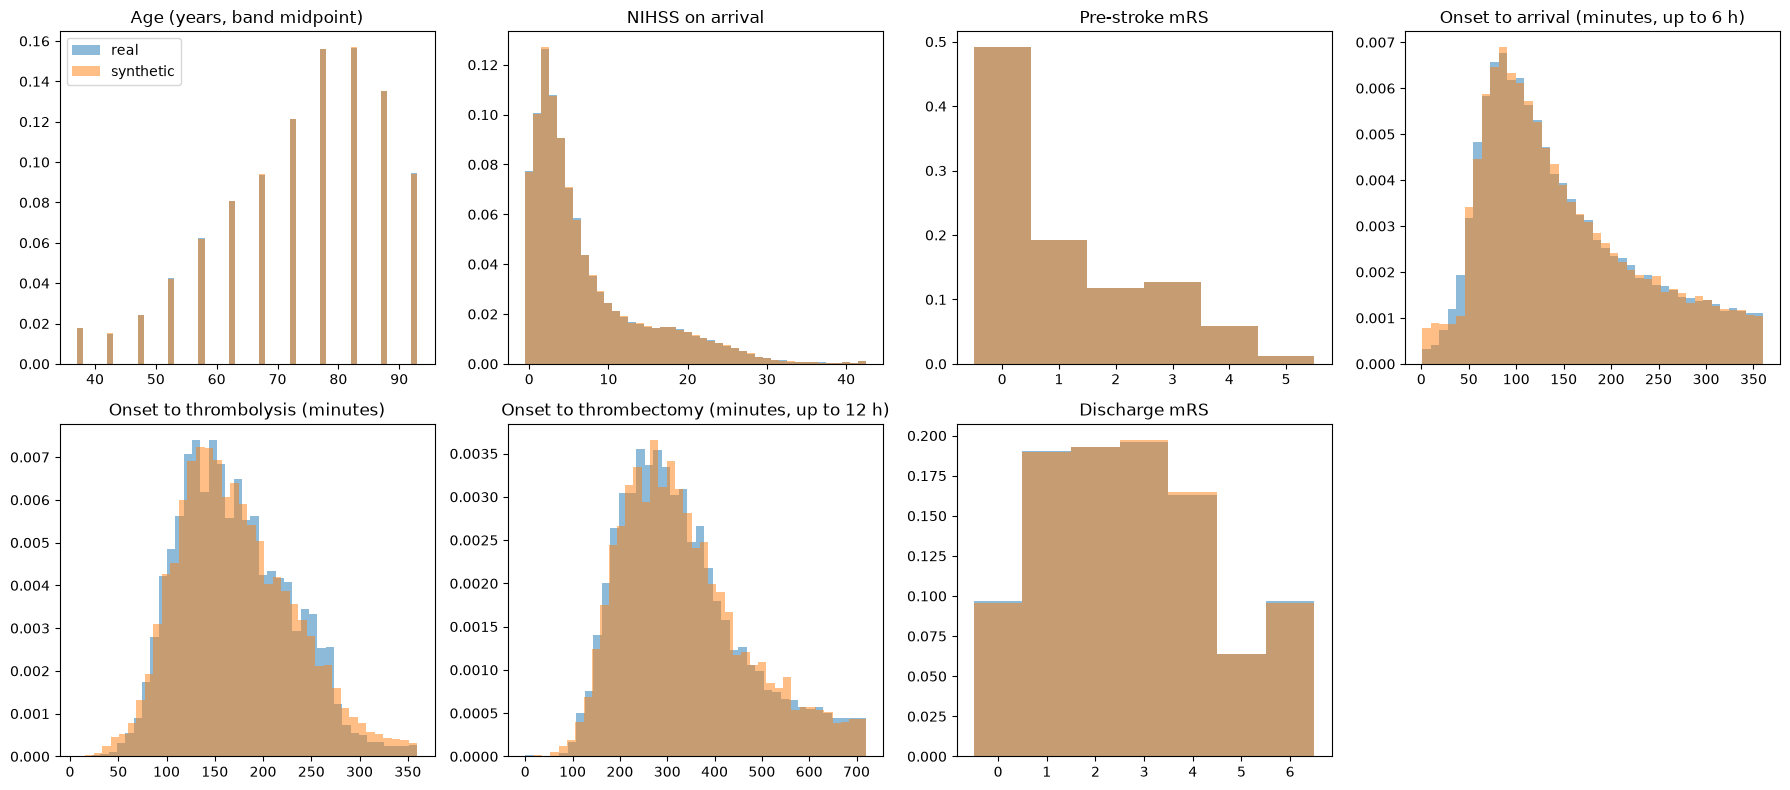

In [9]:
panels = [
    ("age", "Age (years, band midpoint)", None),
    ("stroke_severity", "NIHSS on arrival", None),
    ("prior_disability", "Pre-stroke mRS", None),
    ("onset_to_arrival_time", "Onset to arrival (minutes, up to 6 h)", 360),
    ("onset_to_thrombolysis_time", "Onset to thrombolysis (minutes)", 360),
    ("onset_to_thrombectomy_time", "Onset to thrombectomy (minutes, up to 12 h)", 720),
    ("discharge_disability", "Discharge mRS", None),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (col, label, upper) in zip(axes.ravel(), panels):
    for (name, d), colour in zip(DATASETS.items(), ["#1f77b4", "#ff7f0e"]):
        v = d[col].dropna()
        if upper is not None:
            v = v[v <= upper]
        bins = np.arange(v.min(), v.max() + 2) - 0.5 if v.nunique() < 50 else 40
        ax.hist(v, bins=bins, density=True, alpha=0.5, color=colour, label=name)
    ax.set_title(label)
axes.ravel()[0].legend()
axes.ravel()[-1].axis("off")
fig.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/synthetic_vs_real_distributions.png", dpi=150)
plt.show()

**Results.** The histograms overlap closely for age, NIHSS, pre-stroke mRS, discharge mRS and the three times within the S-learner's limits. The times are smoother in the synthetic data, because values are drawn uniformly within each quantile bin.

### 6.2 Correlations between fields

Spearman (rank) correlations between all numeric fields, treatment indicators and good outcome, in each data set, and their difference. Rank correlation is used because Pearson correlations between treatment times are dominated by a few extreme real times, which are deliberately not reproduced.

Largest absolute difference in pairwise correlation: 0.060
Mean absolute difference: 0.008


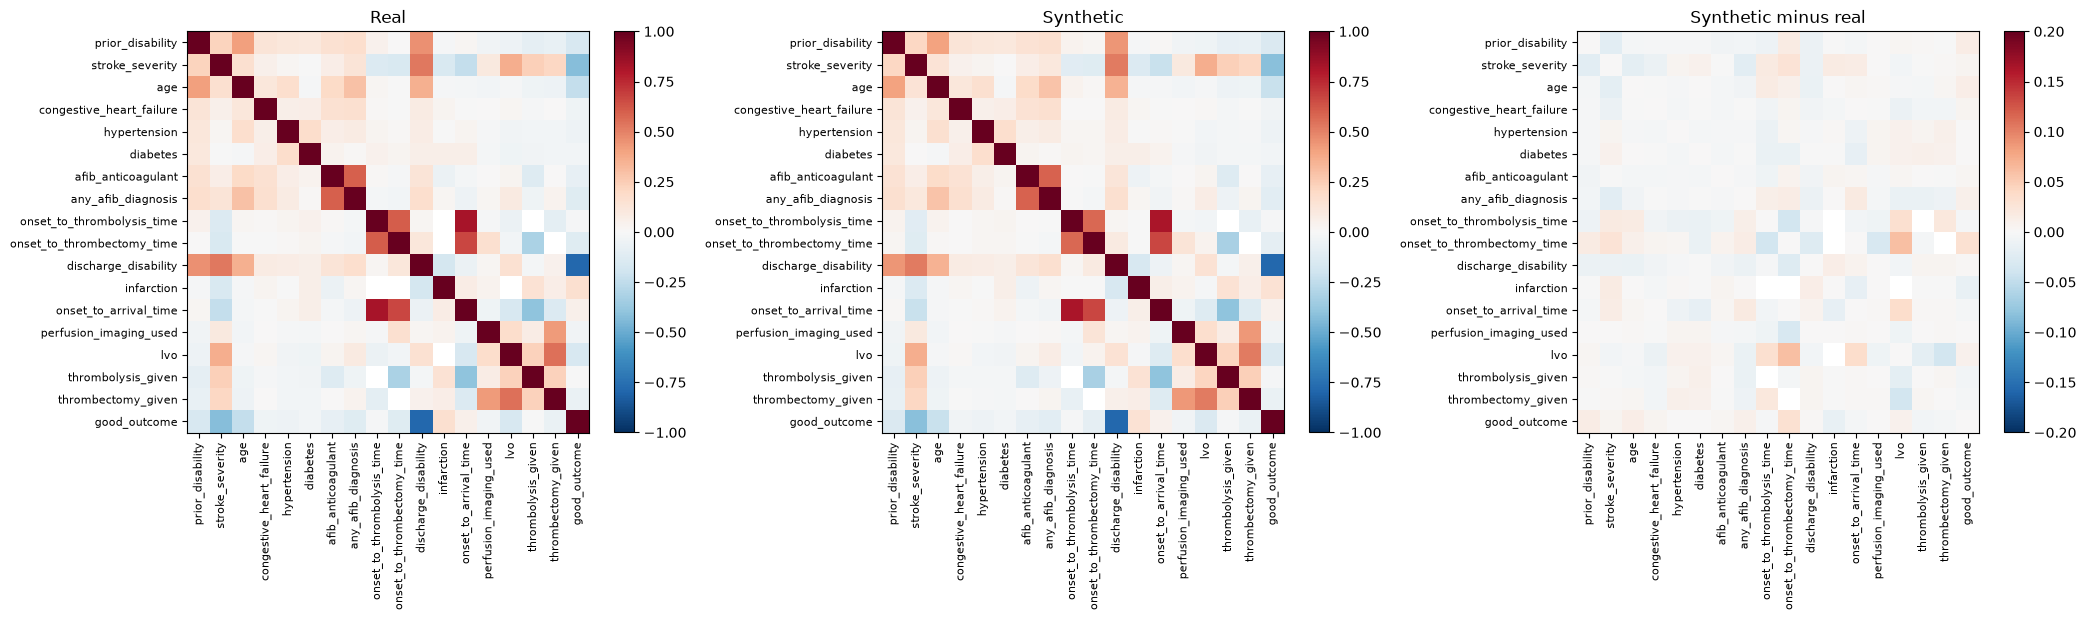

In [10]:
# Spearman (rank) correlation: not dominated by the few extreme times, which are deliberately not reproduced
corr = {name: numeric_view(d).corr(method="spearman") for name, d in DATASETS.items()}
corr_diff = corr["synthetic"] - corr["real"]
off_diagonal = corr_diff.where(~np.eye(len(corr_diff), dtype=bool)).abs()
print(f"Largest absolute difference in pairwise correlation: {off_diagonal.max().max():.3f}")
print(f"Mean absolute difference: {off_diagonal.stack().mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (title, m, vmax) in zip(axes, [("Real", corr["real"], 1), ("Synthetic", corr["synthetic"], 1),
                                       ("Synthetic minus real", corr_diff, 0.2)]):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(len(m)), m.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(m)), m.index, fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/synthetic_vs_real_correlations.png", dpi=150)
plt.show()

**Results.** The largest difference in rank correlation between any two fields is 0.060, and the mean absolute difference is 0.008, so the pairwise relationships between the fields, including those with treatment and good outcome, are reproduced.

### 6.3 Relationship of outcome to features

A logistic regression of good outcome on standardised features and treatment indicators is fitted separately to each data set. Similar coefficients mean the synthetic outcome depends on the features in the same way as the real outcome.

,real,synthetic,difference
prior_disability,0.124,0.126,0.002
stroke_severity,-1.105,-1.092,0.013
age,-0.450,-0.431,0.018
congestive_heart_failure,-0.009,-0.012,-0.003
hypertension,-0.027,-0.025,0.002
diabetes,-0.092,-0.078,0.014
afib_anticoagulant,-0.019,-0.021,-0.002
any_afib_diagnosis,-0.028,-0.028,-0.000
infarction,0.217,0.195,-0.021
thrombolysis_given,0.163,0.149,-0.014


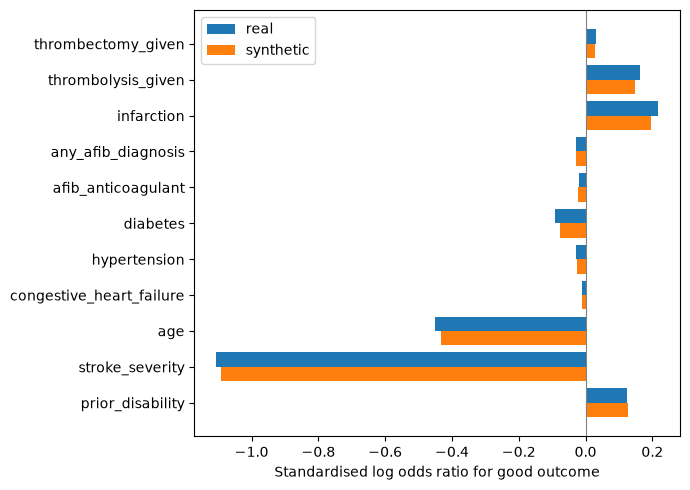

In [11]:
OUTCOME_PREDICTORS = ["prior_disability", "stroke_severity", "age", "congestive_heart_failure",
                      "hypertension", "diabetes", "afib_anticoagulant", "any_afib_diagnosis",
                      "infarction", "thrombolysis_given", "thrombectomy_given"]


def outcome_coefficients(d):
    """Standardised logistic regression coefficients for good outcome (records with outcome and NIHSS)."""
    v = numeric_view(d).dropna(subset=["good_outcome", "stroke_severity"])
    X = StandardScaler().fit_transform(v[OUTCOME_PREDICTORS])
    model = LogisticRegression(max_iter=1000).fit(X, v["good_outcome"])
    return pd.Series(model.coef_[0], index=OUTCOME_PREDICTORS)


coefficients = pd.DataFrame({name: outcome_coefficients(d) for name, d in DATASETS.items()})
coefficients["difference"] = coefficients["synthetic"] - coefficients["real"]
display(coefficients.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
y_pos = np.arange(len(coefficients))
ax.barh(y_pos + 0.2, coefficients["real"], height=0.4, label="real")
ax.barh(y_pos - 0.2, coefficients["synthetic"], height=0.4, label="synthetic")
ax.set_yticks(y_pos, coefficients.index)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Standardised log odds ratio for good outcome")
ax.legend()
fig.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/synthetic_vs_real_outcome_model.png", dpi=150)
plt.show()

**Results.** Every coefficient is within 0.021 of the real one. Stroke severity has by far the strongest association with good outcome in both data sets (−1.105 real, −1.092 synthetic), followed by age (−0.450, −0.431), stroke type (+0.217, +0.195), thrombolysis (+0.163, +0.149) and pre-stroke mRS (+0.124, +0.126; positive because a discharge mRS no worse than before the stroke counts as good). The thrombolysis and thrombectomy coefficients are slightly smaller in the synthetic data.

### 6.4 Outcome by severity, treatment and time to treatment

Good-outcome rates by NIHSS band and treatment received, and by onset-to-treatment time for thrombolysis only and thrombectomy only. These show whether the treatment–outcome and time–outcome relationships, which the S-learner estimates, are reproduced.

In [12]:
def outcome_table(d):
    """Good-outcome rate (%) by NIHSS band and treatment received, and by time to treatment."""
    v = d.assign(good=good_outcome(d)).dropna(subset=["good"])
    treatment = np.select([v["onset_to_thrombolysis_time"].notna() & v["onset_to_thrombectomy_time"].notna(),
                           v["onset_to_thrombolysis_time"].notna(), v["onset_to_thrombectomy_time"].notna()],
                          ["both", "IVT only", "MT only"], "neither")
    nihss = pd.cut(v["stroke_severity"], [-1, 5, 10, 15, 20, 42], labels=["0-5", "6-10", "11-15", "16-20", ">20"])
    by_treatment = (100 * v.groupby([nihss, treatment], observed=True)["good"].mean()).unstack()
    ivt_time = pd.cut(v["onset_to_thrombolysis_time"], [0, 90, 150, 210, 270, 360, np.inf])
    mt_time = pd.cut(v["onset_to_thrombectomy_time"], [0, 180, 270, 360, 480, 720, np.inf])
    ivt_only = treatment == "IVT only"
    mt_only = treatment == "MT only"
    by_ivt_time = 100 * v[ivt_only].groupby(ivt_time[ivt_only], observed=True)["good"].mean()
    by_mt_time = 100 * v[mt_only].groupby(mt_time[mt_only], observed=True)["good"].mean()
    return by_treatment, by_ivt_time, by_mt_time


tables = {name: outcome_table(d) for name, d in DATASETS.items()}
print("Good outcome (%) by NIHSS band (rows) and treatment received (columns)")
display(pd.concat({name: t[0] for name, t in tables.items()}, axis=1).round(1))
print("Good outcome (%) after thrombolysis only, by onset-to-thrombolysis time (minutes)")
display(pd.DataFrame({name: t[1] for name, t in tables.items()}).round(1))
print("Good outcome (%) after thrombectomy only, by onset-to-thrombectomy time (minutes)")
display(pd.DataFrame({name: t[2] for name, t in tables.items()}).round(1))

Good outcome (%) by NIHSS band (rows) and treatment received (columns)


real                       synthetic                      
                IVT only MT only  both neither  IVT only MT only  both neither
stroke_severity                                                               
0-5                 77.2    58.5  64.0    71.7      75.5    68.5  65.8    71.5
6-10                63.1    50.1  61.9    44.5      62.1    42.8  62.5    45.3
11-15               46.7    38.3  49.4    27.6      46.3    34.4  48.1    28.5
16-20               31.6    27.8  36.1    16.4      31.0    27.2  34.1    16.4
>20                 21.5    18.2  25.2    10.2      22.3    18.2  26.0    10.1

Good outcome (%) after thrombolysis only, by onset-to-thrombolysis time (minutes)


,real,synthetic
onset_to_thrombolysis_time,,
"(0.0, 90.0]",62.8,60.0
"(90.0, 150.0]",58.0,57.6
"(150.0, 210.0]",57.7,56.8
"(210.0, 270.0]",57.6,57.0
"(270.0, 360.0]",57.8,54.9
"(360.0, inf]",54.0,54.4


Good outcome (%) after thrombectomy only, by onset-to-thrombectomy time (minutes)


,real,synthetic
onset_to_thrombectomy_time,,
"(0.0, 180.0]",44.5,39.3
"(180.0, 270.0]",37.9,33.4
"(270.0, 360.0]",35.4,34.0
"(360.0, 480.0]",34.5,32.1
"(480.0, 720.0]",33.6,32.3
"(720.0, inf]",28.7,29.4


**Results.**

* **By NIHSS band and treatment:** good-outcome rates fall with severity in every treatment group, as in the real data. For untreated patients, thrombolysis only and both treatments, rates agree within 2.4 percentage points in every band. Thrombectomy only, the smallest group, differs more (for example NIHSS 6–10: 42.8% synthetic vs 50.1% real; NIHSS 0–5: 68.5% vs 58.5%).
* **By time to thrombolysis:** good outcome falls with later treatment in both (from 62.8% at 0–90 minutes to 54.0% after 6 hours in the real data; 60.0% to 54.4% in the synthetic data).
* **By time to thrombectomy:** good outcome falls with later treatment in both (from 44.5% within 3 hours to 28.7% after 12 hours real; 39.3% to 29.4% synthetic), but the early thrombectomy rates are about 5 percentage points lower in the synthetic data.

**Discussion.** The relationships of outcome to severity, treatment and time to treatment are reproduced. The benefit of early thrombectomy is somewhat attenuated, because the regularised outcome model (at least 200 patients per leaf) smooths the effect in the small thrombectomy groups.

### 6.5 Machine learning utility

A gradient-boosted model predicting good outcome is trained on synthetic data and tested on held-out real data ("train synthetic, test real"), and compared with the same model trained and tested on real data. Similar ROC AUCs mean a model learned from the synthetic data behaves like one learned from the real data. (Stroke team and ethnicity are not used, because team names differ between the data sets.)

In [13]:
ML_FEATURES = ["prior_disability", "stroke_severity", "age", "congestive_heart_failure", "hypertension",
               "diabetes", "afib_anticoagulant", "any_afib_diagnosis", "infarction",
               "onset_to_thrombolysis_time", "onset_to_thrombectomy_time"]


def with_outcome(d):
    v = d.assign(good=good_outcome(d)).dropna(subset=["good"])
    return v[ML_FEATURES], v["good"].astype(int)


X_real, y_real = with_outcome(real)
X_train, X_test, y_train, y_test = train_test_split(X_real, y_real, test_size=0.3, random_state=SEED,
                                                    stratify=y_real)
X_syn, y_syn = with_outcome(synthetic)
X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(X_syn, y_syn, test_size=0.3,
                                                                    random_state=SEED, stratify=y_syn)


def auc(X_fit, y_fit, X_eval, y_eval):
    model = HistGradientBoostingClassifier(random_state=SEED).fit(X_fit, y_fit)
    return roc_auc_score(y_eval, model.predict_proba(X_eval)[:, 1])


pd.DataFrame({"ROC AUC": {
    "Train real, test real": auc(X_train, y_train, X_test, y_test),
    "Train synthetic, test real": auc(X_syn_train, y_syn_train, X_test, y_test),
    "Train synthetic, test synthetic": auc(X_syn_train, y_syn_train, X_syn_test, y_syn_test),
}}).round(3)

,ROC AUC
"Train real, test real",0.797
"Train synthetic, test real",0.797
"Train synthetic, test synthetic",0.793


**Results.** A model trained on synthetic data and tested on real data has ROC AUC 0.797, the same as a model trained and tested on real data (0.797). Trained and tested on synthetic data, the AUC is 0.793.

**Discussion.** A model learned from the synthetic data captures the predictive relationships in the real data as well as one learned from the real data, so the synthetic data is suitable for demonstrating machine learning code.

### 6.6 The S-learner's cohort

The S-learner's selection rules (discharge mRS recorded, infarction, arrival within 6 hours, no perfusion imaging, NIHSS > 5 or LVO, teams with at least 10 thrombectomies, plausible treatment times) and its treatment groups (early = thrombolysis within 270 minutes or thrombectomy before 270 minutes) are applied to both data sets. The table shows the number of patients and the good-outcome rate in each treatment group.

In [14]:
CUTOFF = 270


def s_learner_cohort(d):
    """The S-learner's cohort selection and treatment groups."""
    d = d[d["discharge_disability"].notna() & (d["infarction"] == 1) & (d["onset_to_arrival_time"] < 360)
          & (d["perfusion_imaging_used"] == 0) & ((d["stroke_severity"] > 5) | (d["lvo"] == 1))]
    mt_count = d.groupby("stroke_team")["onset_to_thrombectomy_time"].count()
    d = d[d["stroke_team"].isin(mt_count.index[mt_count >= 10])]
    ivt, mt = d["onset_to_thrombolysis_time"], d["onset_to_thrombectomy_time"]
    d = d[~(ivt.notna() & mt.notna() & (ivt > mt)) & (mt.isna() | (mt < 720)) & (ivt.isna() | (ivt < 360))]
    ivt, mt = d["onset_to_thrombolysis_time"], d["onset_to_thrombectomy_time"]
    group = pd.Series("neither", index=d.index)
    group[(ivt <= CUTOFF) & mt.isna()] = "early_thrombolysis_only"
    group[(ivt > CUTOFF) & mt.isna()] = "late_thrombolysis_only"
    group[ivt.isna() & (mt < CUTOFF)] = "early_thrombectomy_only"
    group[ivt.isna() & (mt >= CUTOFF)] = "late_thrombectomy_only"
    group[(ivt <= CUTOFF) & (mt < CUTOFF)] = "early_both"
    group[(ivt <= CUTOFF) & (mt >= CUTOFF)] = "early_thrombolysis_late_thrombectomy"
    group[(ivt > CUTOFF) & (mt > CUTOFF)] = "late_both"
    return d.assign(treatment_group=group, good=good_outcome(d))


GROUPS = ["neither", "early_thrombolysis_only", "late_thrombolysis_only", "early_thrombectomy_only",
          "late_thrombectomy_only", "early_both", "early_thrombolysis_late_thrombectomy", "late_both"]
cohorts = {name: s_learner_cohort(d) for name, d in DATASETS.items()}
print({name: f"{len(c):,} patients, {c['stroke_team'].nunique()} teams" for name, c in cohorts.items()})
pd.concat({name: pd.DataFrame({"n": c["treatment_group"].value_counts(),
                               "good outcome %": 100 * c.groupby("treatment_group")["good"].mean()})
           for name, c in cohorts.items()}, axis=1).reindex(GROUPS).round(1)

{'real': '74,678 patients, 109 teams', 'synthetic': '75,533 patients, 108 teams'}


real                synthetic  \
                                          n good outcome %         n   
treatment_group                                                        
neither                               37647           37.7     38634   
early_thrombolysis_only               27695           49.0     27140   
late_thrombolysis_only                 1189           47.2      1768   
early_thrombectomy_only                1107           38.8       944   
late_thrombectomy_only                 1876           33.6      1981   
early_both                             2309           46.4      2157   
early_thrombolysis_late_thrombectomy   2714           37.2      2695   
late_both                               141           44.0       214   

                                                     
                                     good outcome %  
treatment_group                                      
neither                                        37.0  
early_thrombolysis_only                        48.6  
late_thrombolysis_only                         44.8  
early_thrombectomy_only                        32.3  
late_thrombectomy_only                         29.7  
early_both                                     43.3  
early_thrombolysis_late_thrombectomy           37.2  
late_both                                      36.0

**Results.** The S-learner's selection gives 75,533 synthetic patients from 108 teams, compared with 74,678 real patients from 109 teams.

* Treatment group sizes are similar: untreated 38,634 vs 37,647; early thrombolysis only 27,140 vs 27,695; early both 2,157 vs 2,309. The synthetic data has more late thrombolysis only (1,768 vs 1,189) and late both (214 vs 141).
* Good-outcome rates agree within 0.7 percentage points for untreated patients, early thrombolysis only and early thrombolysis with late thrombectomy, and within 2.4 for late thrombolysis only. The other thrombectomy groups are lower in the synthetic data: early thrombectomy only 32.3% vs 38.8%, late thrombectomy only 29.7% vs 33.6%, early both 43.3% vs 46.4%, late both 36.0% vs 44.0%.

**Discussion.** The S-learner's cohort selection and treatment groups work on the synthetic data and give a cohort of similar size and make-up. An S-learner fitted to the synthetic data should estimate thrombolysis effects similar to the real ones but smaller thrombectomy effects.

## 7. Privacy check

Synthetic records should not reproduce real patients. The real data is split at random into a reference half and a held-out half. Synthetic records are compared with the reference half on every field, and so are the real patients in the held-out half, who were never seen by the comparison: their match rate shows how often matches occur by chance, because many patients share common profiles (for example, no treatment and unknown onset time). The comparison is made with exact times and with times grouped into 30-minute bins. A synthetic match rate no higher than the held-out rate, including for reference records that are unique, shows that the generator has not memorised individual patients.

In [15]:
# Real data with stroke teams given the same anonymous names as in the synthetic data
real_anon = real.assign(stroke_team=real["stroke_team"].map(lambda t: f"Team {team_code[t] + 1:03d}"))
TIME_FIELDS = ["onset_to_arrival_time", "onset_to_thrombolysis_time", "onset_to_thrombectomy_time"]


def record_keys(d, time_bin=None):
    """One hash per record, over all fields; times optionally grouped into bins of time_bin minutes."""
    d = d.copy()
    if time_bin is not None:
        d[TIME_FIELDS] = d[TIME_FIELDS] // time_bin
    return pd.util.hash_pandas_object(d.astype(str), index=False)


# The real data is split at random into a reference half (A) and a held-out half (B). Synthetic records
# are compared with half A, and so are the real patients in half B: real patients that were never seen
# show how often matches occur by chance, because many patients share common profiles.
half_a = rng.random(len(real_anon)) < 0.5
results = {}
for label, time_bin in [("exact times", None), ("times in 30-minute bins", 30)]:
    real_keys = record_keys(real_anon, time_bin)
    reference = real_keys[half_a]
    counts = reference.value_counts()
    unique_reference = set(counts.index[counts == 1])
    for name, keys in [("synthetic records", record_keys(synthetic, time_bin)),
                       ("held-out real records (baseline)", real_keys[~half_a])]:
        results[(label, name)] = {
            "match a reference record (%)": 100 * keys.isin(set(reference)).mean(),
            "match a reference record that is unique (%)": 100 * keys.isin(unique_reference).mean()}
pd.DataFrame(results).T.round(2)

match a reference record (%)  \
exact times             synthetic records                                         1.96   
                        held-out real records (baseline)                          2.07   
times in 30-minute bins synthetic records                                         2.19   
                        held-out real records (baseline)                          2.29   

                                                          match a reference record that is unique (%)  
exact times             synthetic records                                                        1.50  
                        held-out real records (baseline)                                         1.59  
times in 30-minute bins synthetic records                                                        1.72  
                        held-out real records (baseline)                                         1.81

**Results.**

| Comparison with the reference half | Exact times | Times in 30-minute bins |
|---|---|---|
| Synthetic records matching any reference record | 1.96% | 2.19% |
| Held-out real records matching any reference record (baseline) | 2.07% | 2.29% |
| Synthetic records matching a unique reference record | 1.50% | 1.72% |
| Held-out real records matching a unique reference record (baseline) | 1.59% | 1.81% |

**Discussion.** Synthetic records coincide with real records slightly *less* often than real patients who were never seen by the comparison, including for real records that are unique. The matches that do occur are what would be expected from patients sharing common profiles, so there is no evidence that the generator has memorised individual patients. This is a simple record-matching check, not a formal privacy guarantee.

## 8. Save the synthetic data

The synthetic data is saved as a CSV file with the same columns as the real cleaned data.

In [16]:
synthetic.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {len(synthetic):,} synthetic records to {OUTPUT_PATH}")

Saved 452,863 synthetic records to synthetic_data/synthetic_cleaned_data.csv


**Results.** 452,863 synthetic records saved to `data/synthetic/synthetic_cleaned_data.csv` (with the three figures above in the same folder).

## 9. Using the synthetic data, and conclusions

### Using the synthetic data with the S-learner notebook

Set `DATA_PATH = "../data/synthetic/synthetic_cleaned_data.csv"` in the S-learner notebook's settings. The synthetic file contains only the S-learner's fields, so two cells that use other fields will not run and should be skipped: the extended descriptive statistics table (onset-to-scan time and year of admission) and the observed outcomes table (in-hospital death and length of stay). Everything else, including cohort selection, tuning, cross-validation, counterfactual predictions and the sensitivity analyses, uses only the synthetic fields.

### Conclusions

* **Format.** The synthetic data has the same 17 columns, names and types as the real cleaned data, for all 452,863 records, with anonymous stroke team names.
* **Fidelity.** The distribution of every field is reproduced (means and SDs within 0.01 for patient characteristics and discharge mRS; median times within 6 minutes), as are the relationships between fields (rank correlations within 0.06; outcome-model coefficients within 0.021).
* **Outcome related to features.** Good outcome depends on stroke severity, age, pre-stroke disability, treatment and time to treatment as in the real data, and a model trained on synthetic data predicts real outcomes as well as one trained on real data (ROC AUC 0.797).
* **The S-learner's cohort** can be selected from the synthetic data and is of similar size and make-up to the real cohort.
* **Privacy.** Synthetic records match real records no more often than unseen real patients do.

### Limitations

* **Not for inference.** The synthetic data is for demonstrating and testing code. Effect estimates from it will differ from the real ones; in particular, good-outcome rates in the thrombectomy groups are 3 to 8 percentage points lower than in the real data, so thrombectomy effects will be underestimated.
* **Relationships are as good as the generating models.** Each variable depends on the earlier ones through a regularised model, so strong but rare patterns, and interactions in small groups, are smoothed.
* **Tails.** Times above the 99.9th percentile are not reproduced, and times within each bin are uniform, so the long tails of the time distributions differ.
* **Privacy.** The safeguards (anonymous team names, at least 200 patients per model leaf, no extreme values, a record-matching check) reduce disclosure risk but are not a formal privacy guarantee such as differential privacy. Approval should be sought before the synthetic data is shared outside the project.